# Grupo 1 · Áreas quemadas · ¿Mejora el modelo con más imágenes de entrenamiento? (4 → 60 escenas)

Este cuaderno repite el flujo del notebook principal (Prithvi-EO-1.0-100M congelado + Random Forest por parche) con **4, 10, 20, 40 y 60 escenas de entrenamiento**. Todos los tamaños se evalúan en **las mismas 20 escenas de prueba** de `analisis_20_imagenes.ipynb`, así que entre un punto y otro solo cambia cuántas imágenes ve el clasificador.

- **Selección de escenas:** se usa el mismo procedimiento del notebook principal (`subset_archive`), que toma las escenas en el orden del archivo del dataset, sin mirar resultados. Las 4, 10 y 20 escenas están contenidas en las 40, y las 40 en las 60. Las 20 son las mismas de la corrida de Colab.
- **Para cada tamaño se recalcula todo lo que depende del entrenamiento:** la normalización, las representaciones de Prithvi, el Random Forest, el control espectral y la línea base.
- **Métrica principal:** la media por escena de la clase quemada (enunciado, §6), con IC95 % por bootstrap de escenas. El agregado por píxel va como complemento.
- **Equipo:** el mismo portátil sin GPU del análisis con 20 imágenes.

La curva es descriptiva y no se usó para escoger ningún parámetro.

### Resumen

| Escenas de entrenamiento | F1 [IC95] | IoU [IC95] | Precisión | Recall | F1 del control espectral |
|---|---|---|---|---|---|
| 4 (plantilla) | 0.425 [0.32–0.55] | 0.316 [0.21–0.45] | 0.317 | 0.993 | 0.571 |
| 10 | 0.587 [0.46–0.71] | 0.470 [0.35–0.59] | 0.599 | 0.702 | 0.603 |
| 20 (Colab) | 0.633 [0.49–0.76] | 0.524 [0.40–0.64] | 0.746 | 0.604 | 0.654 |
| 40 | 0.663 [0.55–0.77] | 0.543 [0.43–0.65] | 0.773 | 0.652 | 0.639 |
| 60 | 0.703 [0.61–0.79] | 0.578 [0.48–0.68] | 0.813 | 0.699 | 0.644 |

Prithvi + RF, media por escena de la clase quemada en las mismas 20 escenas de prueba.

- **Con más imágenes el modelo mejora, pero más despacio después de 20 escenas.** De 4 a 20 escenas (16 más) el F1 sube 0.21. De 20 a 60 (40 más) sube 0.07 (IC95 de +0.01 a +0.14), y mejora en 12 de las 20 escenas. La IoU sube 0.055 (IC95 de −0.003 a +0.12), justo en el límite de lo que se distingue del azar.
- **De 4 a 20 escenas, el modelo deja de marcar casi todo como quemado:** el recall baja de 0.99 a 0.60 y la precisión sube de 0.32 a 0.75. **De 20 a 60 escenas, encuentra más área quemada:** el recall sube de 0.60 a 0.70 por escena, a cambio de algunos falsos positivos más.
- **Con 40 y 60 escenas, Prithvi queda por encima del control espectral, pero la diferencia no es concluyente.** El control usa solo las bandas con el mismo Random Forest y se estanca desde 20 escenas (IoU de 0.54, 0.52 y 0.53). Prithvi, en cambio, sigue subiendo. Con 60 escenas, la diferencia de IoU es +0.047 (IC95 de −0.013 a +0.109). Con 4 escenas el control es claramente mejor.
- **La mejora viene de las escenas que fallaban.** Las 5 escenas con F1 menor que 0.4 en la corrida de 20 pasan de 0.15 a 0.43 de F1 medio. Las otras 15 se quedan en 0.79–0.80. En el centro y el este, donde el entrenamiento pasa de 6 a 22 escenas, el F1 sube de 0.48 a 0.61.
- **Sigue lejos del techo:** con 60 escenas la IoU es 0.58, frente a 0.81 del techo por bloques de 16×16.
- El portátil sin GPU corrió todo el cuaderno en 3.3 min, con un pico de 1.3 GB de RAM.

## 0. Configuración y utilidades

In [1]:
# --- Configuración de la corrida local ---
import os, sys, json, time, platform
from pathlib import Path
import torch
from importlib.metadata import version

T_INICIO = time.perf_counter()
HERE = Path.cwd()
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
from prithvi_taller import (read_sample, train_normalization, normalize, load_prithvi, features,
                            patch_labels, confusion, metrics, save_json, smoke_test)
from soporte_local import ensure_archive, download_data_local, DATASET_REPO, DATASET_REVISION
print(smoke_test())

TASK = 'quemadas'
CLASSES = [0, 1]
NTEST = 20                          # las mismas 20 escenas de prueba de analisis_20_imagenes.ipynb
CURVA_NTRAIN = [4, 10, 20, 40, 60]  # 4 = valor por defecto de la plantilla; 20 = corrida de Colab
NTRAIN = max(CURVA_NTRAIN)
CACHE = Path(os.environ.get('PRITHVI_CACHE', str(Path.home() / '.cache' / 'prithvi_quemadas')))
OUT = HERE / 'resultados_mas_imagenes'
PREVIO = HERE / 'resultados'        # salidas de analisis_20_imagenes.ipynb, para comprobar que se reproducen
TIMES = {}

Tests de métricas superados; NO prueban descarga ni inferencia.


**Mismo código que el análisis con 20 imágenes.** La celda siguiente es la de utilidades de `analisis_20_imagenes.ipynb`, sin cambios. La de después copia, también sin cambios, sus funciones de evaluación (`evaluate`, `summarize`, `spectral_features`, `paired_diff`) y agrega dos funciones nuevas: `paired_change` (cambio por escena con IC95 %) y `scene_meta` (ubicación de cada escena).

In [2]:
# --- Utilidades de análisis (portables al notebook principal) ---
import re, time, warnings
from pathlib import Path
from datetime import date, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from scipy import ndimage
import rasterio
from rasterio.warp import transform as warp_transform
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='IProgress not found')
if 'TIMES' not in globals():
    TIMES = {}
FIG = OUT / 'figuras'
for d in (OUT, FIG, FIG / 'escenas', OUT / 'escenas'):
    d.mkdir(parents=True, exist_ok=True)

# Paleta validada para daltonismo (azul / naranja / aqua) y tinta neutra para texto y ejes
C = {'modelo': '#2a78d6', 'espectral': '#eb6834', 'base': '#898781',
     'VP': '#1baf7a', 'FP': '#eb6834', 'FN': '#2a78d6', 'VN': '#b5b3ab',
     'ink': '#0b0b0b', 'ink2': '#52514e', 'muted': '#898781', 'grid': '#e1e0d9', 'axis': '#c3c2b7',
     'surface': '#fcfcfb', 'quemado': '#52514e', 'noquemado': '#e9e8e3', 'ignorado': '#ffffff',
     'seq': ['#86b6ef', '#2a78d6', '#104281']}
plt.rcParams.update({
    'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'savefig.facecolor': C['surface'],
    'axes.edgecolor': C['axis'], 'axes.labelcolor': C['ink2'], 'axes.titlecolor': C['ink'],
    'xtick.color': C['axis'], 'ytick.color': C['axis'], 'xtick.labelcolor': C['ink2'], 'ytick.labelcolor': C['ink2'],
    'text.color': C['ink'], 'grid.color': C['grid'], 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9.5, 'axes.titlesize': 10.5,
    'legend.frameon': False, 'figure.dpi': 100, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})

def scene_id(path):
    """'subsetted_512x512_HLS.S30.T10TEK.2018340.v1.4_merged.tif' -> 'T10TEK.2018340' (tile MGRS . año + día juliano)."""
    m = re.search(r'HLS\.S30\.(T\w{5})\.(\d{7})', Path(path).name)
    return f'{m.group(1)}.{m.group(2)}'

def doy_to_date(code):
    return date(int(code[:4]), 1, 1) + timedelta(days=int(code[4:]) - 1)

def stretch(a):
    a = a.copy()
    for c in range(a.shape[2]):
        v = a[:, :, c]; ok = np.isfinite(v)
        if ok.any():
            lo, hi = np.percentile(v[ok], [2, 98]); a[:, :, c] = np.clip((v - lo) / max(hi - lo, 1e-6), 0, 1)
    return np.nan_to_num(a)

def display_rgb(x):    # color verdadero (rojo, verde, azul), igual que en el notebook principal
    return stretch(x[[2, 1, 0], 0].transpose(1, 2, 0))

def display_false(x):  # falso color SWIR2-NIR-rojo: cicatriz rojiza/morada, vegetación verde, agua oscura
    return stretch(x[[5, 3, 2], 0].transpose(1, 2, 0))

def mask_rgb(y):
    out = np.zeros(y.shape + (3,))
    out[y == 1] = to_rgb(C['quemado']); out[y == 0] = to_rgb(C['noquemado']); out[y < 0] = to_rgb(C['ignorado'])
    return out

def error_rgb(x, y, pred, alpha=0.85):
    g = display_rgb(x).mean(axis=2)
    out = np.repeat((0.35 + 0.6 * g)[..., None], 3, axis=2)        # fondo gris claro (la escena)
    for cat, m in [('VP', (y == 1) & (pred == 1)), ('FP', (y == 0) & (pred == 1)), ('FN', (y == 1) & (pred == 0))]:
        out[m] = (1 - alpha) * out[m] + alpha * np.array(to_rgb(C[cat]))
    out[y < 0] = to_rgb(C['ignorado'])
    return out

LEG_ERR = [Patch(color=C['VP'], label='Quemado detectado (VP)'), Patch(color=C['FP'], label='Falso positivo (FP)'),
           Patch(color=C['FN'], label='Falso negativo (FN)'), Patch(facecolor=C['ignorado'], edgecolor=C['axis'], label='Ignorado (−1)')]
LEG_MASK = [Patch(color=C['quemado'], label='Quemado (1)'), Patch(color=C['noquemado'], label='No quemado (0)'),
            Patch(facecolor=C['ignorado'], edgecolor=C['axis'], label='Ignorado (−1)')]

def to_grid(a):
    """(..., 224, 224) -> (..., 14, 14, 256): bloques 16×16 en el mismo orden que patch_labels y los tokens."""
    s = a.shape[:-2]
    return a.reshape(*s, 14, 16, 14, 16).swapaxes(-3, -2).reshape(*s, 14, 14, 256)

def up(grid):
    return np.repeat(np.repeat(grid, 16, axis=0), 16, axis=1)

def boot_ci(v, B=10000, seed=0):
    """IC95 % de la media por escena: bootstrap remuestreando ESCENAS (no píxeles)."""
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    if len(v) == 0:
        return np.array([np.nan, np.nan])
    idx = np.random.default_rng(seed).integers(0, len(v), size=(B, len(v)))
    return np.percentile(v[idx].mean(axis=1), [2.5, 97.5])

def region(sid):
    """Agrupación geográfica por zona UTM del tile MGRS: 10–13 = Oeste (lon < −102°), 14–18 = Centro-Este."""
    return 'Oeste' if int(sid[1:3]) <= 13 else 'Centro-Este'

def indices(x_raw):
    """Índices espectrales por píxel a partir de reflectancia (bandas: azul, verde, rojo, NIR B8A, SWIR1, SWIR2)."""
    b, g, r, nir, sw1, sw2 = x_raw[:, 0]
    with np.errstate(invalid='ignore', divide='ignore'):
        return {'NBR': (nir - sw2) / (nir + sw2), 'NDVI': (nir - r) / (nir + r), 'NBR2': (sw1 - sw2) / (sw1 + sw2),
                'NIR (B8A)': nir, 'SWIR2': sw2, 'Brillo visible': (b + g + r) / 3}

def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2)**2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2)**2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

# Mismo flujo que las celdas 21 y 23 del notebook principal, en funciones reutilizables
def extract(rows):
    return [features(model, device, x) for x, _ in rows]

def train_head(F_train, rows_train):
    feats, targets = [], []
    for f, (_, y) in zip(F_train, rows_train):
        lab = patch_labels(y); v = lab >= 0
        feats.append(f[v]); targets.append(lab[v])
    X_, Y_ = np.concatenate(feats), np.concatenate(targets)
    h = RandomForestClassifier(n_estimators=80, max_depth=10, class_weight='balanced', random_state=42, n_jobs=2)
    return h.fit(X_, Y_), X_, Y_

def train_majority(rows_raw):
    lab = np.concatenate([y[y >= 0] for _, y in rows_raw])
    values, counts = np.unique(lab, return_counts=True)
    return int(values[np.argmax(counts)]), dict(zip(values.tolist(), counts.tolist()))

def predict_grid(h, f):
    return h.predict(f.reshape(-1, f.shape[-1])).reshape(14, 14)

In [3]:
# Funciones copiadas sin cambios de analisis_20_imagenes.ipynb

def ram_gb():
    try:
        import ctypes
        class MEMSTAT(ctypes.Structure):
            _fields_ = [('dwLength', ctypes.c_ulong), ('dwMemoryLoad', ctypes.c_ulong)] + \
                       [(n, ctypes.c_ulonglong) for n in ['ullTotalPhys', 'ullAvailPhys', 'ullTotalPageFile', 'ullAvailPageFile',
                                                         'ullTotalVirtual', 'ullAvailVirtual', 'ullAvailExtendedVirtual']]
        m = MEMSTAT(); m.dwLength = ctypes.sizeof(MEMSTAT)
        ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(m))
        return m.ullTotalPhys / 1024**3, m.ullAvailPhys / 1024**3
    except Exception:
        info = dict(l.split(':', 1) for l in Path('/proc/meminfo').read_text().splitlines())
        kb = lambda k: float(info[k].split()[0]) / 1024**2
        return kb('MemTotal'), kb('MemAvailable')

def peak_ram_gb():
    """Pico de memoria de este proceso (Windows: PeakWorkingSetSize; Linux: ru_maxrss)."""
    try:
        import ctypes
        from ctypes import wintypes
        class PMC(ctypes.Structure):
            _fields_ = [('cb', wintypes.DWORD), ('PageFaultCount', wintypes.DWORD)] + \
                       [(n, ctypes.c_size_t) for n in ['PeakWorkingSetSize', 'WorkingSetSize', 'QuotaPeakPagedPoolUsage',
                        'QuotaPagedPoolUsage', 'QuotaPeakNonPagedPoolUsage', 'QuotaNonPagedPoolUsage', 'PagefileUsage', 'PeakPagefileUsage']]
        pmc = PMC(); pmc.cb = ctypes.sizeof(PMC)
        k32 = ctypes.windll.kernel32; k32.GetCurrentProcess.restype = wintypes.HANDLE
        f = ctypes.windll.psapi.GetProcessMemoryInfo
        f.argtypes = [wintypes.HANDLE, ctypes.POINTER(PMC), wintypes.DWORD]
        f(k32.GetCurrentProcess(), ctypes.byref(pmc), pmc.cb)
        return pmc.PeakWorkingSetSize / 1024**3
    except Exception:
        import resource
        return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

def cpu_name():
    try:
        import winreg
        k = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r'HARDWARE\DESCRIPTION\System\CentralProcessor\0')
        return winreg.QueryValueEx(k, 'ProcessorNameString')[0].strip()
    except Exception:
        try:
            return next(l.split(':', 1)[1].strip() for l in Path('/proc/cpuinfo').read_text().splitlines() if l.startswith('model name'))
        except Exception:
            return platform.processor()

def evaluate(grids, rows_test, maj, method):
    """Métricas por escena de la clase 1 para `method` y para la línea base, con la misma máscara de válidos."""
    out, mats = [], {method: [], 'linea_base': []}
    for i, (grid, (_, y)) in enumerate(zip(grids, rows_test)):
        for name, p in [(method, up(grid)), ('linea_base', np.full(y.shape, maj, dtype=np.int64))]:
            mat = confusion(y, p, CLASSES); mats[name].append(mat)
            m1 = metrics(mat, CLASSES)[1]
            out.append({'i': i, 'escena': ids['test'][i], 'metodo': name, 'vp': int(mat[1, 1]), 'fp': int(mat[0, 1]),
                        'fn': int(mat[1, 0]), 'vn': int(mat[0, 0]), 'soporte_1': m1['support'], 'iou': m1['iou'],
                        'f1': m1['f1'], 'precision': m1['precision'], 'recall': m1['recall']})
    d = pd.DataFrame(out)
    with np.errstate(invalid='ignore', divide='ignore'):
        d['exactitud'] = (d.vp + d.vn) / (d.vp + d.vn + d.fp + d.fn)
        d['iou_0'] = np.where(d.vn + d.fp + d.fn > 0, d.vn / (d.vn + d.fp + d.fn), np.nan)
    return d, mats

def summarize(df, mats, subset=None):
    rows = []
    for name in df.metodo.unique():
        d = df[df.metodo == name]
        if subset is not None:
            d = d[d.escena.isin(subset)]
        pooled = metrics(sum(mats[name][i] for i in d.i), CLASSES)[1]
        row = {'método': name, 'escenas': len(d), 'escenas con IoU definido': int(d.iou.notna().sum())}
        for col, lab in [('iou', 'IoU'), ('f1', 'F1'), ('precision', 'Precisión'), ('recall', 'Recall')]:
            lo, hi = boot_ci(d[col])
            row[f'{lab} media escena'] = d[col].mean(); row[f'{lab} IC95'] = f'{lo:.3f}–{hi:.3f}'
        for col, lab in [('iou', 'IoU'), ('f1', 'F1'), ('precision', 'Precisión'), ('recall', 'Recall')]:
            row[f'{lab} agregado píxel'] = pooled[col]
        rows.append(row)
    return pd.DataFrame(rows).set_index('método')

def spectral_features(x_norm, x_raw):
    g = to_grid(x_norm[:, 0])                                   # (6, 14, 14, 256)
    feats = [g.mean(-1), g.std(-1)]
    ix = indices(x_raw)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        for k in ['NBR', 'NDVI', 'NBR2']:
            feats.append(np.nan_to_num(np.nanmean(to_grid(ix[k]), axis=-1))[None])
    return np.concatenate(feats, axis=0).transpose(1, 2, 0)

def paired_diff(a, b, B=10000, seed=0):
    d = np.asarray(a, float) - np.asarray(b, float); d = d[np.isfinite(d)]
    idx = np.random.default_rng(seed).integers(0, len(d), size=(B, len(d)))
    lo, hi = np.percentile(d[idx].mean(1), [2.5, 97.5])
    return {'diferencia media': d.mean(), 'IC95': f'{lo:+.3f} a {hi:+.3f}', 'escenas donde Prithvi gana': f'{(d > 0).sum()}/{len(d)}'}


# Funciones nuevas de este cuaderno
def paired_change(new, old, B=10000, seed=0):
    """Cambio medio por escena (new − old) con IC95 % por bootstrap pareado de escenas."""
    d = np.asarray(new, float) - np.asarray(old, float); d = d[np.isfinite(d)]
    idx = np.random.default_rng(seed).integers(0, len(d), size=(B, len(d)))
    lo, hi = np.percentile(d[idx].mean(1), [2.5, 97.5])
    return {'cambio medio': d.mean(), 'IC95 bajo': lo, 'IC95 alto': hi, 'escenas que suben': int((d > 0).sum()),
            'escenas que bajan': int((d < 0).sum()), 'escenas': len(d)}

def scene_meta(im):
    """Centro (lat, lon) y límites de la escena 512 y del recorte central 224 que ve el modelo."""
    with rasterio.open(im) as f:
        b, res_m, h, w, crs = f.bounds, f.res[0], f.height, f.width, f.crs
    lon, lat = warp_transform(crs, 'EPSG:4326', [(b.left + b.right) / 2], [(b.bottom + b.top) / 2])
    r0, c0 = (h - 224) // 2, (w - 224) // 2
    b224 = (b.left + c0 * res_m, b.top - (r0 + 224) * res_m, b.left + (c0 + 224) * res_m, b.top - r0 * res_m)
    return {'crs': crs.to_string(), 'lat': lat[0], 'lon': lon[0], 'bounds': tuple(b), 'bounds_224': b224}

def overlap(b1, b2):
    return not (b1[2] <= b2[0] or b2[2] <= b1[0] or b1[3] <= b2[1] or b2[3] <= b1[1])

## 1. Equipo y versiones

In [4]:
total, free = ram_gb()
hardware = {'cpu': cpu_name(), 'nucleos_logicos': os.cpu_count(), 'ram_total_gb': round(total, 1),
            'ram_disponible_al_iniciar_gb': round(free, 1), 'gpu_cuda': torch.cuda.is_available(),
            'torch_hilos': torch.get_num_threads(), 'python': platform.python_version(), 'so': platform.platform()}
packages = {p: version(p) for p in ['torch', 'torchvision', 'timm', 'numpy', 'scikit-learn', 'scipy', 'rasterio', 'pandas', 'matplotlib']}
display(pd.Series({**hardware, **{'paquete ' + k: v for k, v in packages.items()}}, name='valor').to_frame())

,valor
cpu,Intel(R) Core(TM) i5-1035G1 CPU @ 1.00GHz
nucleos_logicos,8
ram_total_gb,7.7
ram_disponible_al_iniciar_gb,0.8
gpu_cuda,False
torch_hilos,4
python,3.13.5
so,Windows-11-10.0.26300-SP0
paquete torch,2.7.1
paquete torchvision,0.22.1


## 2. Datos: las mismas 20 escenas de prueba y entrenamiento anidado
Para cada tamaño se pide al procedimiento de selección `NTRAIN` escenas de entrenamiento y 20 de prueba. Se verifica que la prueba sea idéntica en todas las corridas y que cada conjunto de entrenamiento contenga al anterior.

In [5]:
COLAB_TRAIN = ['T10TEK.2018340', 'T11SMT.2019294', 'T11TKE.2018215', 'T11TMF.2019312', 'T11TMJ.2018217',
               'T12STC.2020218', 'T12SUH.2020188', 'T12SVC.2019245', 'T12SVD.2018168', 'T12TUK.2020286',
               'T13SFB.2020189', 'T13TCJ.2020200', 'T13TCM.2020250', 'T13TEF.2019109', 'T14SLA.2020193',
               'T15RTM.2020059', 'T15SXA.2018154', 'T16RFT.2019250', 'T16SDB.2018063', 'T17RMJ.2018064']
PRUEBA_20 = ['T10TGK.2020285', 'T10TGL.2018215', 'T11SLB.2018197', 'T11SMU.2020299', 'T11TMF.2020217',
             'T11TPH.2020249', 'T11TQG.2018221', 'T12RVV.2020320', 'T12SUJ.2019308', 'T12SXA.2020247',
             'T12TVK.2020308', 'T14RNV.2018215', 'T14SKF.2019246', 'T15TVN.2018135', 'T15TVN.2019140',
             'T16REV.2019135', 'T16SDC.2018098', 'T16SGE.2019100', 'T17SNU.2018129', 'T18SVJ.2020131']

archive = ensure_archive(CACHE)            # el mismo tar verificado con SHA-256
sel = {}
for n in CURVA_NTRAIN:
    t0 = time.perf_counter()
    p, nbytes = download_data_local(archive, CACHE / 'datos' / f'train{n}_test{NTEST}', n, NTEST)
    sel[n] = {'pairs': p, 'bytes': nbytes, 's': time.perf_counter() - t0}
TIMES['seleccion_por_configuracion_s'] = {f'{n}/{NTEST}': round(v['s'], 1) for n, v in sel.items()}
pairs = sel[NTRAIN]['pairs']
ids = {s: [scene_id(im) for im, _ in rows] for s, rows in pairs.items()}
CURVA_IDS = {n: [scene_id(im) for im, _ in sel[n]['pairs']['train']] for n in CURVA_NTRAIN}
test_ids = {n: [scene_id(im) for im, _ in sel[n]['pairs']['test']] for n in CURVA_NTRAIN}
checks = {
    'La prueba es la misma en todas las corridas': all(v == ids['test'] for v in test_ids.values()),
    'Y son las 20 escenas de analisis_20_imagenes.ipynb (mismo orden)': ids['test'] == PRUEBA_20,
    'Entrenamiento anidado (' + ' ⊂ '.join(map(str, CURVA_NTRAIN)) + ')':
        all(set(CURVA_IDS[a]) <= set(CURVA_IDS[b]) for a, b in zip(CURVA_NTRAIN, CURVA_NTRAIN[1:])),
    'Las 20 de entrenamiento son las de Colab': sorted(CURVA_IDS[20]) == sorted(COLAB_TRAIN),
    'Ninguna escena de prueba está en el entrenamiento': not set(ids['test']) & set(ids['train']),
}
display(pd.DataFrame([{'train/test': f'{n}/{NTEST}', 'bytes comprimidos leídos': v['bytes'], 'segundos': round(v['s'], 1)}
                      for n, v in sel.items()]))
display(pd.Series(checks, name='verificación').to_frame())
assert all(checks.values()), 'La selección no cumple lo esperado: revisar antes de seguir.'
for a, b in zip(CURVA_NTRAIN, CURVA_NTRAIN[1:]):
    nuevas = sorted(set(CURVA_IDS[b]) - set(CURVA_IDS[a]))
    print(f'De {a} a {b} escenas entran {len(nuevas)}: {sum(region(s) == "Oeste" for s in nuevas)} del oeste y '
          f'{sum(region(s) != "Oeste" for s in nuevas)} del centro y el este')

,train/test,bytes comprimidos leídos,segundos
0,4/20,1916559360,0.0
1,10/20,1916559360,0.0
2,20/20,1916559360,0.0
3,40/20,1916559360,0.0
4,60/20,1916559360,0.0


,verificación
La prueba es la misma en todas las corridas,True
Y son las 20 escenas de analisis_20_imagenes.ipynb (mismo orden),True
Entrenamiento anidado (4 ⊂ 10 ⊂ 20 ⊂ 40 ⊂ 60),True
Las 20 de entrenamiento son las de Colab,True
Ninguna escena de prueba está en el entrenamiento,True


De 4 a 10 escenas entran 6: 3 del oeste y 3 del centro y el este
De 10 a 20 escenas entran 10: 7 del oeste y 3 del centro y el este
De 20 a 40 escenas entran 20: 12 del oeste y 8 del centro y el este
De 40 a 60 escenas entran 20: 12 del oeste y 8 del centro y el este


In [6]:
t0 = time.perf_counter()
samples = {split: [read_sample(TASK, im, lab) for im, lab in rows] for split, rows in pairs.items()}
TIMES['lectura_s'] = time.perf_counter() - t0
for split, rows in samples.items():
    for x, y in rows:
        assert x.shape == (6, 1, 224, 224) and y.shape == (224, 224)
        if not np.isin(y[y >= 0], CLASSES).all():
            raise ValueError('Etiqueta fuera de leyenda; revisar la versión.')
print({s: len(r) for s, r in samples.items()}, '| lectura y recorte:', round(TIMES['lectura_s'], 1), 's')

# Composición de cada conjunto de entrenamiento y cercanía con la prueba (posible fuga espacial)
meta = pd.DataFrame([{'split': s, 'escena': scene_id(im), **scene_meta(im)} for s, rows in pairs.items() for im, _ in rows])
te_meta = meta[meta.split == 'test']
comp = []
for n in CURVA_NTRAIN:
    k = [ids['train'].index(s) for s in CURVA_IDS[n]]
    lab = np.stack([samples['train'][j][1] for j in k])
    pl = np.stack([patch_labels(samples['train'][j][1]) for j in k])
    tr = meta[(meta.split == 'train') & meta.escena.isin(CURVA_IDS[n])]
    tiles = {s[:6] for s in tr.escena}
    s512 = s224 = mismo_tile = 0
    for _, r in te_meta.iterrows():
        same = tr[tr.crs == r.crs]
        s512 += any(overlap(r.bounds, b) for b in same.bounds)
        s224 += any(overlap(r.bounds_224, b) for b in same.bounds_224)
        mismo_tile += r.escena[:6] in tiles
    comp.append({'escenas de entrenamiento': n, 'del oeste': sum(region(s) == 'Oeste' for s in CURVA_IDS[n]),
                 'del centro y el este': sum(region(s) != 'Oeste' for s in CURVA_IDS[n]),
                 '% píxeles quemados': 100 * (lab == 1).sum() / (lab >= 0).sum(),
                 'parches 16×16 válidos': int((pl >= 0).sum()), '% parches quemados': 100 * (pl == 1).sum() / (pl >= 0).sum(),
                 'pruebas en un tile de entrenamiento': mismo_tile, 'pruebas cuya escena 512 toca una de entrenamiento': s512,
                 'pruebas cuyo recorte 224 toca uno de entrenamiento': s224})
comp = pd.DataFrame(comp).set_index('escenas de entrenamiento')
display(comp.round(1))
print('Escenas de prueba por región:', pd.Series([region(s) for s in ids['test']]).value_counts().to_dict())

{'train': 60, 'test': 20} | lectura y recorte: 7.9 s


,del oeste,del centro y el este,% píxeles quemados,parches 16×16 válidos,% parches quemados,pruebas en un tile de entrenamiento,pruebas cuya escena 512 toca una de entrenamiento,pruebas cuyo recorte 224 toca uno de entrenamiento
escenas de entrenamiento,,,,,,,,
4,4,0,64.0,784,63.9,0,0,0
10,7,3,52.7,1960,52.3,1,1,0
20,14,6,37.8,3920,37.6,1,1,0
40,26,14,38.6,7830,38.6,1,1,0
60,38,22,38.6,11750,38.5,3,1,0


Escenas de prueba por región: {'Oeste': 11, 'Centro-Este': 9}


- **Las 20 escenas de prueba son las mismas en los cinco tamaños, y cada conjunto de entrenamiento contiene al anterior.** De 20 a 40 escenas y de 40 a 60 entran 20 escenas cada vez: 12 del oeste y 8 del centro y el este. Así, el centro y el este pasan de 6 a 14 y luego a 22 escenas de entrenamiento.
- **El balance de clases casi no cambia desde 20 escenas:** los parches quemados son el 37.6 %, el 38.6 % y el 38.5 % con 20, 40 y 60 escenas, frente al 63.9 % y el 52.3 % con 4 y 10. De 20 a 60 escenas cambia la variedad de paisajes, no la proporción de área quemada.
- **No hay fuga espacial en lo que ve el modelo:** ningún recorte 224 de prueba toca uno de entrenamiento. Con 60 escenas, 3 escenas de prueba comparten tile (un cuadro de 110 km) con alguna de entrenamiento. Desde 10 escenas, una escena 512 de prueba toca una de entrenamiento, pero sus recortes no se tocan.

## 3. Modelo

In [7]:
t0 = time.perf_counter()
T = samples['train'][0][0].shape[1]
model, device, model_info = load_prithvi(CACHE / 'modelo', num_frames=T)
TIMES['carga_modelo_s'] = time.perf_counter() - t0
model_info['checkpoint'] = Path(model_info['checkpoint']).name   # sin rutas locales en la procedencia
provenance = {'task': TASK, 'model': model_info, 'ntrain_curva': CURVA_NTRAIN, 'ntest': NTEST, 'classes': CLASSES,
              'crop': 'center224_pad_ignore', 'normalization': 'train_zscore_by_band (recalculada para cada tamaño)',
              'head': 'RandomForest(n_estimators=80, max_depth=10, class_weight=balanced, random_state=42), patch16 majority, frozen encoder',
              'dataset': {'repo': DATASET_REPO, 'revision': DATASET_REVISION}, 'hardware': hardware, 'packages': packages,
              'ejecucion': 'local en CPU; seleccion de escenas con el mismo procedimiento que el notebook principal'}
save_json(OUT / 'procedencia.json', provenance)
print(model_info, '| carga del modelo:', round(TIMES['carga_modelo_s'], 1), 's')

{'repo': 'ibm-nasa-geospatial/Prithvi-EO-1.0-100M', 'revision': '7b231fe5b0684e2ddd40c967fbc02e225ef77dc6', 'checkpoint': 'Prithvi_100M.pt', 'device': 'cpu', 'num_frames': 1} | carga del modelo: 11.6 s


## 4. Curva: el mismo flujo con cada tamaño de entrenamiento
Para cada tamaño se repite el bucle de la sección 11 de `analisis_20_imagenes.ipynb`: normalización con las escenas de ese tamaño, representaciones de Prithvi, Random Forest, control espectral (15 rasgos por parche con el mismo Random Forest) y línea base (clase mayoritaria del entrenamiento). Después se comprueba que los puntos de 4, 10 y 20 escenas coinciden con los de ese cuaderno.

In [8]:
curve, curve_scene, TIMES['por_tamano_s'] = [], [], {}
for n in CURVA_NTRAIN:
    t0 = time.perf_counter()
    k = [ids['train'].index(s) for s in CURVA_IDS[n]]
    tr_raw = [samples['train'][j] for j in k]
    m_n, s_n = train_normalization(tr_raw)
    prep_tr = [(normalize(x, m_n, s_n), y) for x, y in tr_raw]
    prep_te = [(normalize(x, m_n, s_n), y) for x, y in samples['test']]
    Ftr, Fte = extract(prep_tr), extract(prep_te)
    maj_n, cnt_n = train_majority(tr_raw)
    h_n, _, Y_n = train_head(Ftr, prep_tr)
    d_p, mt_p = evaluate([predict_grid(h_n, f) for f in Fte], prep_te, maj_n, 'prithvi_rf')
    Str = [spectral_features(xn, xr) for (xn, _), (xr, _) in zip(prep_tr, tr_raw)]
    Ste = [spectral_features(xn, xr) for (xn, _), (xr, _) in zip(prep_te, samples['test'])]
    hs_n, _, _ = train_head(Str, prep_tr)
    d_s, mt_s = evaluate([predict_grid(hs_n, s) for s in Ste], prep_te, maj_n, 'control_espectral')
    allm = pd.concat([d_p, d_s[d_s.metodo == 'control_espectral']], ignore_index=True)
    allmats = {**mt_p, 'control_espectral': mt_s['control_espectral']}
    for name in ['prithvi_rf', 'control_espectral', 'linea_base']:
        d = allm[allm.metodo == name]; pooled = metrics(sum(allmats[name]), CLASSES)[1]
        row = {'ntrain': n, 'metodo': name, 'parches_entrenamiento': len(Y_n), '% parches quemados train': 100 * (Y_n == 1).mean(),
               'clase_linea_base': maj_n, 'iou_agregado': pooled['iou'], 'f1_agregado': pooled['f1']}
        for met in ['iou', 'f1', 'precision', 'recall']:
            lo, hi = boot_ci(d[met]); row.update({f'{met}_media': d[met].mean(), f'{met}_lo': lo, f'{met}_hi': hi})
        row.update({'precision_agregado': pooled['precision'], 'recall_agregado': pooled['recall']})
        curve.append(row)
    curve_scene.append(allm.assign(ntrain=n))
    TIMES['por_tamano_s'][n] = round(time.perf_counter() - t0, 1)
    print(f'{n:>2} escenas de entrenamiento: {TIMES["por_tamano_s"][n]:5.1f} s | '
          f'F1 por escena de Prithvi + RF = {d_p[d_p.metodo == "prithvi_rf"].f1.mean():.3f}')
cv = pd.DataFrame(curve)
cs = pd.concat(curve_scene, ignore_index=True)

 4 escenas de entrenamiento:  14.3 s | F1 por escena de Prithvi + RF = 0.425


10 escenas de entrenamiento:  17.7 s | F1 por escena de Prithvi + RF = 0.587


20 escenas de entrenamiento:  23.4 s | F1 por escena de Prithvi + RF = 0.633


40 escenas de entrenamiento:  40.9 s | F1 por escena de Prithvi + RF = 0.663


60 escenas de entrenamiento:  57.8 s | F1 por escena de Prithvi + RF = 0.703


In [9]:
# ¿Se reproducen los puntos de 4, 10 y 20 escenas de analisis_20_imagenes.ipynb?
prev = pd.read_csv(PREVIO / 'curva_aprendizaje.csv')
cols = [c for c in prev.columns if c not in ('ntrain', 'metodo')]
a = prev.set_index(['ntrain', 'metodo'])[cols]
b = cv.set_index(['ntrain', 'metodo']).loc[a.index, cols]
dif = float((a - b).abs().max().max())
print(f'Diferencia máxima frente a curva_aprendizaje.csv ({len(a)} filas × {len(cols)} columnas): {dif:.1e}')
assert dif < 1e-6, 'Los puntos ya publicados no se reproducen: revisar antes de seguir.'

# Techo por parche: mejor resultado posible prediciendo por bloques de 16×16 (usa las etiquetas; no depende del entrenamiento)
orc = []
for i, (_, y) in enumerate(samples['test']):
    blk = to_grid(y); n0 = (blk == 0).sum(-1); n1 = (blk == 1).sum(-1)
    m1 = metrics(confusion(y, up((n1 > n0).astype(np.int64)), CLASSES), CLASSES)[1]
    orc.append({'i': i, 'escena': ids['test'][i], 'iou': m1['iou'], 'f1': m1['f1'], 'precision': m1['precision'], 'recall': m1['recall']})
orc = pd.DataFrame(orc)
TECHO = orc[['iou', 'f1', 'precision', 'recall']].mean().to_dict()
print('Techo por parche (media por escena):', {k: round(v, 3) for k, v in TECHO.items()})

def fmt(r, met):
    return f"{r[f'{met}_media']:.3f} [{r[f'{met}_lo']:.2f}–{r[f'{met}_hi']:.2f}]"
get = lambda n, name: cv[(cv.ntrain == n) & (cv.metodo == name)].iloc[0]
tabla = pd.DataFrame([{
    'escenas de entrenamiento': n,
    'F1 [IC95]': fmt(get(n, 'prithvi_rf'), 'f1'), 'IoU [IC95]': fmt(get(n, 'prithvi_rf'), 'iou'),
    'Precisión [IC95]': fmt(get(n, 'prithvi_rf'), 'precision'), 'Recall [IC95]': fmt(get(n, 'prithvi_rf'), 'recall'),
    'F1 agregado píxel': round(get(n, 'prithvi_rf').f1_agregado, 3), 'IoU agregado píxel': round(get(n, 'prithvi_rf').iou_agregado, 3),
    'Control espectral F1': round(get(n, 'control_espectral').f1_media, 3),
    'Control espectral IoU': round(get(n, 'control_espectral').iou_media, 3),
    'Línea base F1': round(get(n, 'linea_base').f1_media, 3), 'Clase de la línea base': int(get(n, 'linea_base').clase_linea_base)}
    for n in CURVA_NTRAIN]).set_index('escenas de entrenamiento')
print('Prithvi + RF, media por escena en las mismas 20 escenas de prueba:')
display(tabla)

Diferencia máxima frente a curva_aprendizaje.csv (9 filas × 17 columnas): 1.1e-16
Techo por parche (media por escena): {'iou': 0.806, 'f1': 0.89, 'precision': 0.896, 'recall': 0.884}


Prithvi + RF, media por escena en las mismas 20 escenas de prueba:


,F1 [IC95],IoU [IC95],Precisión [IC95],Recall [IC95],F1 agregado píxel,IoU agregado píxel,Control espectral F1,Control espectral IoU,Línea base F1,Clase de la línea base
escenas de entrenamiento,,,,,,,,,,
4,0.425 [0.32–0.55],0.316 [0.21–0.45],0.317 [0.21–0.45],0.993 [0.99–1.00],0.478,0.314,0.571,0.454,0.358,1
10,0.587 [0.46–0.71],0.470 [0.35–0.59],0.599 [0.46–0.73],0.702 [0.55–0.84],0.695,0.532,0.603,0.483,0.358,1
20,0.633 [0.49–0.76],0.524 [0.40–0.64],0.746 [0.60–0.87],0.604 [0.46–0.74],0.747,0.596,0.654,0.543,0.000,0
40,0.663 [0.55–0.77],0.543 [0.43–0.65],0.773 [0.66–0.87],0.652 [0.51–0.78],0.772,0.629,0.639,0.523,0.000,0
60,0.703 [0.61–0.79],0.578 [0.48–0.68],0.813 [0.74–0.88],0.699 [0.58–0.81],0.797,0.662,0.644,0.531,0.000,0


## 5. Gráfica: cómo cambian las métricas al aumentar las imágenes

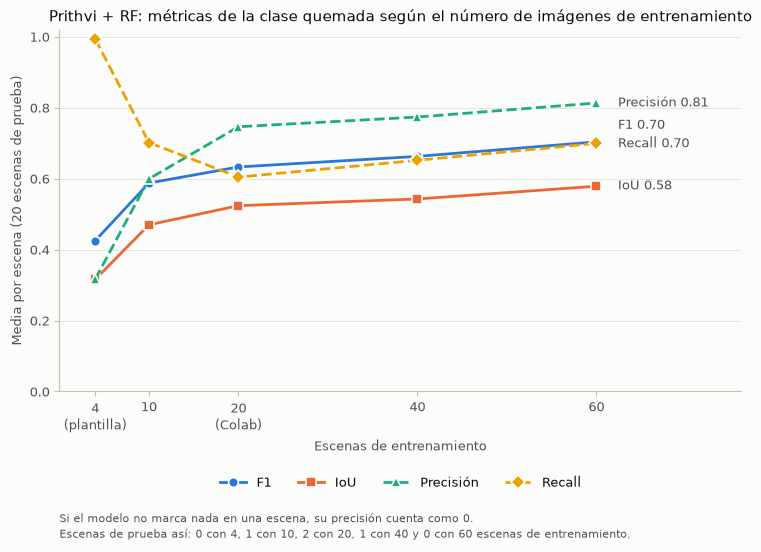

In [10]:
MET = [('f1', 'F1', '#2a78d6', '-', 'o'), ('iou', 'IoU', '#eb6834', '-', 's'),
       ('precision', 'Precisión', '#1baf7a', '--', '^'), ('recall', 'Recall', '#eda100', '--', 'D')]
TICKS = {4: '4\n(plantilla)', 20: '20\n(Colab)'}
p = cv[cv.metodo == 'prithvi_rf'].set_index('ntrain')
fig, ax = plt.subplots(figsize=(8.8, 4.7))
for met, lab, col, ls, mk in MET:
    ax.plot(p.index, p[f'{met}_media'], color=col, lw=2, ls=ls, marker=mk, ms=7, label=lab,
            markeredgecolor=C['surface'], markeredgewidth=1.2, zorder=3)
ends = {lab: p[f'{met}_media'].iloc[-1] for met, lab, *_ in MET}
ypos, last = {}, -1.0
for lab in sorted(ends, key=ends.get):              # etiquetas al final de cada línea, sin encimarse
    ypos[lab] = max(ends[lab], last + 0.05); last = ypos[lab]
for lab, v in ends.items():
    ax.annotate(f'{lab} {v:.2f}', (p.index[-1], v), xytext=(p.index[-1] + 0.04 * p.index[-1], ypos[lab]),
                textcoords='data', va='center', fontsize=9, color=C['ink2'])
ax.set_xticks(CURVA_NTRAIN); ax.set_xticklabels([TICKS.get(n, str(n)) for n in CURVA_NTRAIN])
ax.set_xlim(0, p.index[-1] * 1.27); ax.set_ylim(0, 1.02); ax.yaxis.grid(True)
ax.set_xlabel('Escenas de entrenamiento'); ax.set_ylabel(f'Media por escena ({NTEST} escenas de prueba)')
ax.set_title('Prithvi + RF: métricas de la clase quemada según el número de imágenes de entrenamiento')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4)
sin_pred = cs[cs.metodo == 'prithvi_rf'].assign(s=lambda d: (d.vp + d.fp) == 0).groupby('ntrain').s.sum()
partes = [f'{int(v)} con {n}' for n, v in sin_pred.items()]
ax.text(0, -0.33, 'Si el modelo no marca nada en una escena, su precisión cuenta como 0.\nEscenas de prueba así: '
        + ', '.join(partes[:-1]) + f' y {partes[-1]} escenas de entrenamiento.',
        transform=ax.transAxes, va='top', fontsize=8, color=C['ink2'], linespacing=1.4)
fig.savefig(FIG / '12_metricas_segun_imagenes.png'); plt.show()

- **De 4 a 20 escenas cambia el comportamiento del modelo.** Con las 4 escenas de la plantilla (64 % de parches quemados) marca casi todo como quemado: recall de 0.99 y precisión de 0.32. Con 20 escenas la proporción baja al 38 % y el modelo se vuelve prudente: precisión de 0.75 y recall de 0.60.
- **De 20 a 60 escenas, lo que más cambia es el recall.** Sube de 0.60 a 0.70 por escena y de 0.64 a 0.75 en el agregado por píxel. Los píxeles quemados sin detectar (FN) bajan de 94 168 a 66 855, y los falsos positivos suben de 20 776 a 33 881.
- **Cuidado al leer la precisión.** La media por escena sube de 0.75 a 0.81, pero sobre todo porque con 20 escenas había dos escenas de prueba donde el modelo no marcaba nada, y en ellas la precisión cuenta como 0 (nota de la gráfica). Sin esas dos escenas, la precisión media es 0.83 con 20 y 0.81 con 60. En el agregado por píxel baja de 0.89 a 0.85.
- **El F1 y la IoU suben cada vez más despacio.** El F1 pasa de 0.43 a 0.63 entre 4 y 20 escenas, y de 0.63 a 0.70 entre 20 y 60. En el agregado por píxel pasa de 0.75 a 0.80 entre 20 y 60.

## 6. ¿Con más imágenes Prithvi supera a las bandas solas?

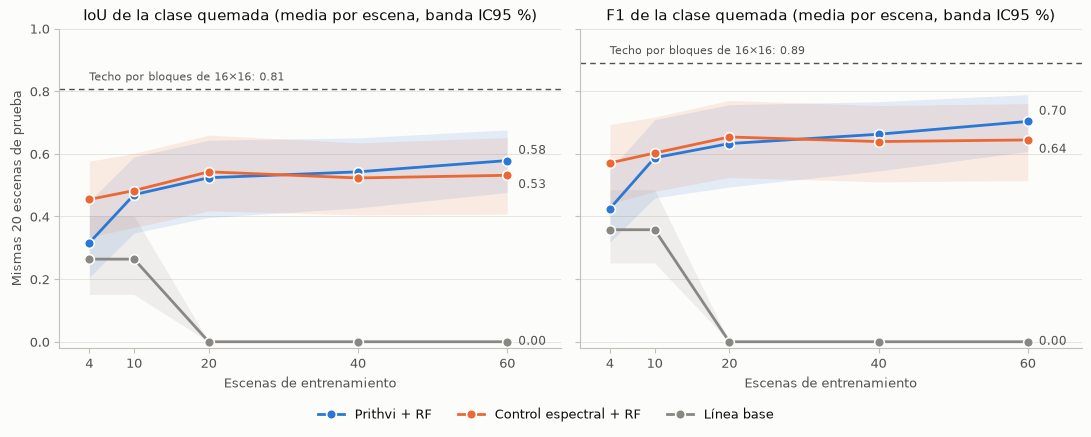

In [11]:
SERIES = [('prithvi_rf', 'Prithvi + RF', C['modelo']), ('control_espectral', 'Control espectral + RF', C['espectral']),
          ('linea_base', 'Línea base', C['base'])]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), sharey=True)
for ax, met, lab in zip(axes, ['iou', 'f1'], ['IoU', 'F1']):
    ax.axhline(TECHO[met], color=C['ink2'], lw=1, ls=(0, (4, 3)))
    ax.text(CURVA_NTRAIN[0], TECHO[met] + 0.02, f'Techo por bloques de 16×16: {TECHO[met]:.2f}', fontsize=8, color=C['ink2'], va='bottom')
    ends = {name: cv[cv.metodo == name].iloc[-1][f'{met}_media'] for name, _, _ in SERIES}
    top = max(['prithvi_rf', 'control_espectral'], key=ends.get)
    for name, label, color in SERIES:
        d = cv[cv.metodo == name]
        ax.plot(d.ntrain, d[f'{met}_media'], color=color, lw=2, marker='o', ms=7, label=label,
                markeredgecolor=C['surface'], markeredgewidth=1.2)
        ax.fill_between(d.ntrain, d[f'{met}_lo'], d[f'{met}_hi'], color=color, alpha=0.12, lw=0)
        dy = 0 if name == 'linea_base' else (7 if name == top else -7)
        ax.annotate(f'{ends[name]:.2f}', (d.ntrain.iloc[-1], ends[name]), xytext=(8, dy),
                    textcoords='offset points', va='center', fontsize=8.5, color=C['ink2'])
    ax.set_xticks(CURVA_NTRAIN); ax.set_xlim(0, max(CURVA_NTRAIN) * 1.12); ax.set_ylim(-0.02, 1.0)
    ax.set_xlabel('Escenas de entrenamiento'); ax.set_title(f'{lab} de la clase quemada (media por escena, banda IC95 %)')
    ax.yaxis.grid(True)
axes[0].set_ylabel(f'Mismas {NTEST} escenas de prueba')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); fig.savefig(FIG / '13_prithvi_vs_bandas_segun_imagenes.png'); plt.show()

In [12]:
pr = cs[cs.metodo == 'prithvi_rf'].pivot(index='i', columns='ntrain', values=['iou', 'f1'])
sp = cs[cs.metodo == 'control_espectral'].pivot(index='i', columns='ntrain', values=['iou', 'f1'])
NOM = {'iou': 'IoU', 'f1': 'F1'}
cambios = pd.DataFrame([{'comparación': f'Prithvi: {n} frente a 20 escenas', 'métrica': NOM[met], **paired_change(pr[met][n], pr[met][20])}
                        for n in CURVA_NTRAIN if n != 20 for met in ['iou', 'f1']])
print('¿Cambia Prithvi + RF al pasar de 20 escenas (Colab) a otro tamaño? (bootstrap pareado de escenas)')
display(cambios.round(3))
vs_control = pd.DataFrame([{'escenas de entrenamiento': n, 'métrica': NOM[met], **paired_change(pr[met][n], sp[met][n])}
                           for n in CURVA_NTRAIN for met in ['iou', 'f1']])
vs_control = vs_control.rename(columns={'cambio medio': 'Prithvi − control', 'escenas que suben': 'escenas donde gana Prithvi',
                                        'escenas que bajan': 'escenas donde gana el control'})
print('Prithvi + RF frente al control espectral con el mismo Random Forest y las mismas escenas:')
display(vs_control.round(3))

¿Cambia Prithvi + RF al pasar de 20 escenas (Colab) a otro tamaño? (bootstrap pareado de escenas)


,comparación,métrica,cambio medio,IC95 bajo,IC95 alto,escenas que suben,escenas que bajan,escenas
0,Prithvi: 4 frente a 20 escenas,IoU,-0.208,-0.341,-0.059,6,14,20
1,Prithvi: 4 frente a 20 escenas,F1,-0.208,-0.339,-0.062,6,14,20
2,Prithvi: 10 frente a 20 escenas,IoU,-0.054,-0.142,0.038,6,13,20
3,Prithvi: 10 frente a 20 escenas,F1,-0.045,-0.138,0.054,6,13,20
4,Prithvi: 40 frente a 20 escenas,IoU,0.019,-0.027,0.067,9,10,20
5,Prithvi: 40 frente a 20 escenas,F1,0.030,-0.018,0.081,9,10,20
6,Prithvi: 60 frente a 20 escenas,IoU,0.055,-0.003,0.117,12,7,20
7,Prithvi: 60 frente a 20 escenas,F1,0.071,0.007,0.144,12,7,20


Prithvi + RF frente al control espectral con el mismo Random Forest y las mismas escenas:


,escenas de entrenamiento,métrica,Prithvi − control,IC95 bajo,IC95 alto,escenas donde gana Prithvi,escenas donde gana el control,escenas
0,4,IoU,-0.138,-0.248,-0.016,4,15,20
1,4,F1,-0.146,-0.258,-0.023,4,15,20
2,10,IoU,-0.013,-0.089,0.066,8,11,20
3,10,F1,-0.015,-0.093,0.066,8,11,20
4,20,IoU,-0.019,-0.062,0.029,7,12,20
5,20,F1,-0.021,-0.065,0.026,7,12,20
6,40,IoU,0.020,-0.048,0.085,11,7,20
7,40,F1,0.023,-0.044,0.090,11,7,20
8,60,IoU,0.047,-0.013,0.109,10,8,20
9,60,F1,0.059,-0.005,0.128,10,8,20


- **Prithvi mejora con más imágenes y las bandas solas no.** El control espectral sube hasta 20 escenas y ahí se queda: IoU de 0.54, 0.52 y 0.53 con 20, 40 y 60. Prithvi pasa de 0.52 a 0.54 y a 0.58. Una explicación posible es que el Random Forest necesita más ejemplos para aprovechar 768 rasgos que 15. Con 4 escenas pasa lo contrario: el control es claramente mejor (IoU −0.14 para Prithvi, IC95 de −0.25 a −0.02).
- **Con 60 escenas Prithvi queda adelante, pero no es concluyente.** La diferencia es +0.047 de IoU (IC95 de −0.013 a +0.109) y +0.059 de F1 (IC95 de −0.005 a +0.128). Prithvi gana en 10 escenas, el control en 8 y en 2 empatan. En el agregado por píxel también queda adelante (IoU de 0.66 frente a 0.62).
- **Frente a la corrida de Colab (20 escenas):** con 60 escenas, el F1 de Prithvi sube 0.071 (IC95 de +0.007 a +0.144) y la IoU 0.055 (IC95 de −0.003 a +0.117). La mejora del F1 se distingue del cero, aunque por poco; la de la IoU queda justo en el límite. Con 40 escenas, el cambio todavía no se distingue del azar (F1 +0.030, IC95 de −0.018 a +0.081).
- **La brecha con el techo sigue grande:** con 60 escenas la IoU es 0.58 y el techo por bloques es 0.81. Más imágenes ayudan, pero no quitan el límite de predecir por bloques de 480 m.

## 7. ¿Qué escenas mejoran con más imágenes?

In [13]:
# Las 5 escenas con F1 < 0.4 con 20 escenas de entrenamiento: su área quemada tiene NBR positivo (analisis_20_imagenes.ipynb, sección 10.1)
DIFICILES = ['T11SLB.2018197', 'T15TVN.2019140', 'T16REV.2019135', 'T16SDC.2018098', 'T17SNU.2018129']
f1p = pr['f1'].copy(); f1p.index = [ids['test'][i] for i in f1p.index]
assert sorted(f1p.index[f1p[20] < 0.4]) == sorted(DIFICILES)
oeste = [s for s in f1p.index if region(s) == 'Oeste']; centro = [s for s in f1p.index if region(s) != 'Oeste']
grupos = pd.DataFrame({f'Las {len(DIFICILES)} difíciles (NBR positivo)': f1p.loc[DIFICILES].mean(),
                       f'Las otras {len(f1p) - len(DIFICILES)}': f1p.drop(DIFICILES).mean(),
                       f'Oeste ({len(oeste)} escenas de prueba)': f1p.loc[oeste].mean(),
                       f'Centro y este ({len(centro)} escenas de prueba)': f1p.loc[centro].mean()}).T
grupos.columns = [f'{n} escenas' for n in grupos.columns]
print('F1 medio de Prithvi + RF por grupo de escenas de prueba:')
display(grupos.round(3))
print('Escenas de entrenamiento por región:', {n: (int(comp.loc[n, 'del oeste']), int(comp.loc[n, 'del centro y el este'])) for n in CURVA_NTRAIN},
      '(oeste, centro y este)')

por_escena = f1p.copy(); por_escena.columns = [f'F1 con {n}' for n in por_escena.columns]
por_escena.insert(0, 'región', [region(s) for s in por_escena.index])
por_escena.insert(1, 'difícil', por_escena.index.isin(DIFICILES))
por_escena[f'cambio 20 → {NTRAIN}'] = f1p[NTRAIN] - f1p[20]
display(por_escena.sort_values(f'cambio 20 → {NTRAIN}').round(3))

F1 medio de Prithvi + RF por grupo de escenas de prueba:


,4 escenas,10 escenas,20 escenas,40 escenas,60 escenas
Las 5 difíciles (NBR positivo),0.310,0.311,0.149,0.306,0.425
Las otras 15,0.464,0.679,0.794,0.781,0.796
Oeste (11 escenas de prueba),0.545,0.642,0.757,0.739,0.781
Centro y este (9 escenas de prueba),0.279,0.521,0.481,0.569,0.609


Escenas de entrenamiento por región: {4: (4, 0), 10: (7, 3), 20: (14, 6), 40: (26, 14), 60: (38, 22)} (oeste, centro y este)


,región,difícil,F1 con 4,F1 con 10,F1 con 20,F1 con 40,F1 con 60,cambio 20 → 60
T14SKF.2019246,Centro-Este,False,0.515,0.671,0.678,0.547,0.547,-0.131
T10TGL.2018215,Oeste,False,0.381,0.523,0.819,0.709,0.720,-0.099
T12TVK.2020308,Oeste,False,0.545,0.783,0.890,0.839,0.832,-0.058
T12SUJ.2019308,Oeste,False,0.504,0.802,0.863,0.846,0.809,-0.054
T11TMF.2020217,Oeste,False,0.191,0.313,0.667,0.598,0.640,-0.027
T12SXA.2020247,Oeste,False,0.476,0.712,0.719,0.702,0.701,-0.018
T16SGE.2019100,Centro-Este,False,0.167,0.324,0.677,0.800,0.671,-0.006
T14RNV.2018215,Centro-Este,False,0.592,0.866,0.884,0.876,0.884,0.000
T15TVN.2018135,Centro-Este,False,0.325,0.812,0.804,0.835,0.805,0.001
T11TQG.2018221,Oeste,False,0.377,0.809,0.896,0.886,0.899,0.003


- **La mejora se concentra en las escenas que fallaban.** Las 5 escenas con F1 menor que 0.4 en la corrida de 20 suben de 0.15 a 0.31 (40 escenas) y a 0.43 (60). El modelo empieza a detectar parte de esas cicatrices: su recall medio pasa de 0.09 a 0.32. Las otras 15 casi no cambian (0.79, 0.78 y 0.80).
- **El centro y el este se acercan al oeste.** Con 6, 14 y 22 escenas de entrenamiento de esa región, su F1 es 0.48, 0.57 y 0.61, mientras el oeste se mantiene (0.76, 0.74 y 0.78). Esto apoya que parte de la falla en esa región era falta de ejemplos de esos paisajes.
- **Esto matiza lo que vimos con 20 escenas:** que el área quemada tenga NBR positivo no era una barrera fija. Con más ejemplos, el modelo detecta parte de esas cicatrices poco visibles: T15TVN.2019140 pasa de 0 a 0.58 y T16SDC.2018098, de 0.38 a 0.63.
- **Pero no todo se arregla con más datos.** T11SLB es el *Lions Fire*: su etiqueta es el perímetro final del incendio, pero la imagen es de la mitad del incendio. Solo llega a 0.38, y T17SNU a 0.15. Siguen entre las peores, como se espera si parte del problema está en la etiqueta.
- **Las escenas difíciles son inestables:** el F1 de T15TVN.2019140 es 0.27, 0.50, 0.00, 0.25 y 0.58 con 4, 10, 20, 40 y 60 escenas. Su resultado depende mucho de qué escenas entran al entrenamiento. Por eso conviene mirar el promedio y no cada escena, y recordar que con otro orden de escenas la curva cambiaría algo.
- **Algunas escenas empeoran:** 7 de las 20 bajan entre 20 y 60 escenas. La que más baja es T14SKF.2019246, de 0.68 a 0.55.

## 8. Exportar resultados

In [14]:
cv.to_csv(OUT / 'curva_mas_imagenes.csv', index=False)
cs.to_csv(OUT / 'curva_mas_imagenes_por_escena.csv', index=False)
tabla.to_csv(OUT / 'tabla_resumen.csv')
comp.to_csv(OUT / 'composicion_entrenamiento.csv')
cambios.to_csv(OUT / 'cambio_frente_a_20_escenas.csv', index=False)
vs_control.to_csv(OUT / 'prithvi_vs_control_por_tamano.csv', index=False)
grupos.to_csv(OUT / 'f1_por_grupo_de_escenas.csv')
por_escena.to_csv(OUT / 'f1_por_escena_y_tamano.csv')
orc.to_csv(OUT / 'techo_por_parche_por_escena.csv', index=False)
for d in (FIG / 'escenas', OUT / 'escenas'):      # carpetas que crea la celda de utilidades y aquí no se usan
    if d.exists() and not any(d.iterdir()):
        d.rmdir()
TIMES['pico_ram_proceso_gb'] = round(peak_ram_gb(), 2)
TIMES['total_min'] = round((time.perf_counter() - T_INICIO) / 60, 1)
save_json(OUT / 'tiempos.json', TIMES)
print(sorted(str(p.relative_to(OUT)) for p in OUT.rglob('*') if p.is_file()))

['cambio_frente_a_20_escenas.csv', 'composicion_entrenamiento.csv', 'curva_mas_imagenes.csv', 'curva_mas_imagenes_por_escena.csv', 'f1_por_escena_y_tamano.csv', 'f1_por_grupo_de_escenas.csv', 'figuras\\12_metricas_segun_imagenes.png', 'figuras\\13_prithvi_vs_bandas_segun_imagenes.png', 'prithvi_vs_control_por_tamano.csv', 'procedencia.json', 'tabla_resumen.csv', 'techo_por_parche_por_escena.csv', 'tiempos.json']


## 9. Tiempos y memoria

In [15]:
display(pd.Series({k: v for k, v in TIMES.items()}, name='valor').to_frame())

,valor
seleccion_por_configuracion_s,"{'4/20': 0.0, '10/20': 0.0, '20/20': 0.0, '40/..."
lectura_s,7.872288
carga_modelo_s,11.649082
por_tamano_s,"{4: 14.3, 10: 17.7, 20: 23.4, 40: 40.9, 60: 57.8}"
pico_ram_proceso_gb,1.32
total_min,3.3


**Cómo leer estos tiempos.** En esta ejecución el cuaderno completo tardó 3.3 min, con el portátil conectado a la corriente. Las selecciones de escenas ya estaban guardadas en disco (0 s). En la primera ejecución, seleccionar 40 y 60 escenas desde el archivo local tardó 60 s y 54 s, y el cuaderno completo, 4.7 min. Cada tamaño tomó de 14 s con 4 escenas a 58 s con 60, incluyendo la normalización, las representaciones de Prithvi para entrenamiento y prueba, los dos Random Forest y la evaluación. El pico de memoria del proceso fue de 1.3 GB. Para esta curva no hace falta GPU.

## 10. Conclusiones

1. **Más imágenes de entrenamiento mejoran el modelo, pero cada vez menos.** Con 60 escenas, el F1 por escena es 0.70 y la IoU 0.58. Con las 20 escenas de Colab eran 0.63 y 0.52, y con las 4 de la plantilla, 0.43 y 0.32. Agregar 16 escenas (de 4 a 20) sube el F1 0.21; agregar 40 (de 20 a 60) lo sube 0.07.
2. **De 20 a 60 escenas, el modelo encuentra más área quemada:** el recall pasa de 0.60 a 0.70, con algunos falsos positivos más. La subida de la precisión media por escena se explica sobre todo por dos escenas donde antes no marcaba nada.
3. **Con 40 y 60 escenas, Prithvi supera al control espectral, que se estanca desde 20.** Pero con 20 escenas de prueba la diferencia (+0.05 de IoU con 60) no es concluyente, y con 4 escenas el control es claramente mejor. Esto es compatible con que Prithvi, con 768 rasgos, necesite más ejemplos para rendir que un control de 15 rasgos espectrales.
4. **La mejora viene sobre todo de las escenas difíciles y del centro y el este**, la región que más escenas ganó en el entrenamiento. Las escenas con problemas de etiqueta, como el *Lions Fire*, siguen entre las peores.
5. **Más datos no quitan el límite del método:** con 60 escenas, la IoU (0.58) sigue lejos del techo por bloques de 16×16 (0.81).
6. **Limitaciones.** Es una sola secuencia de escenas, la que entrega el procedimiento de selección, con 20 escenas de prueba y 60 de las 540 escenas de entrenamiento disponibles. El resultado de las escenas difíciles cambia mucho según qué escenas entran al entrenamiento. La curva es descriptiva y no se usó para escoger nada.